# Rebalancing Bluebikes Across Greater Boston — 2026 Crew Plan
**IE 5374 Applied Generative AI · Module 7 Hackathon**

**Pipeline:** Bluebikes trips (2024-01 → 2026-09) → station-hour net flow → simulated rebalancing need → LLM event extraction (structured output) → event-aware 2026 forecast → integer-programming crew plan (full-time + seasonal) → backtest on Jan–Sep 2026 → sensitivity → tool-calling operations assistant.

**GenAI techniques used:** (1) API calls + prompt engineering, (2) structured output (JSON → Pydantic validation), (3) agent with tool calling.

> **AI-use statement:** Parts of this notebook's code were drafted with an AI assistant (Claude) and then reviewed, run and edited by the team. AI-assisted sections are marked `AI-assisted`. All results shown are from our own runs.

In [1]:
# !pip install pandas numpy scipy requests pyarrow matplotlib openai pydantic
import os, io, json, zipfile, math
from pathlib import Path
from datetime import date
import numpy as np, pandas as pd, requests, matplotlib.pyplot as plt
from scipy.optimize import milp, LinearConstraint, Bounds
import scipy.sparse as sp

DATA = Path("data"); DATA.mkdir(exist_ok=True)
BASE = "https://s3.amazonaws.com/hubway-data"
STATION_SRC = "https://assets.ctfassets.net/p6ae3zqfb1e3/3BswRZgQMp0f8XWBLY6T19/60da57a4630102788a127902bfda9888/-External-_Bluebikes_Station_List__updated_08.21.26_.csv"   # official Bluebikes Station List (Aug 2026), bluebikes.com/system-data
STATION_LOCAL = "bluebikes_stations.csv"   # optional: a local copy of the same file (used first if present)
MONTHS = pd.period_range("2024-01", "2026-09", freq="M")

CITIES = ["Boston", "Cambridge", "Somerville", "Brookline", "Other"]   # 'Other' = all remaining cities, sharing crews
INIT_CREWS = {"Boston": 6, "Cambridge": 4, "Somerville": 1, "Brookline": 1, "Other": 2}   # Jan 2026, assumed full-time

# ---- ASSUMED parameters from the brief ----
BIKES_PER_SHIFT, SHIFTS_PER_WEEK = 120, 6
CAP_DAY = BIKES_PER_SHIFT * SHIFTS_PER_WEEK / 7          # avg bikes one crew moves per calendar day (~102.9)
FT_SALARY, VAN_MONTHLY = 54_000, 1_500
FT_MONTHLY = FT_SALARY / 12 + VAN_MONTHLY                # $6,000 per full-time crew-month
RELEASE_COST = 0.25 * FT_SALARY                          # $13,500 severance
SEASONAL_MONTHLY, SEASONAL_CAP, SEASONAL_MIN = 7_800, 8, 3
RIDE_REV = 3.25
LOSS_PER_FAILED = 0.40 * 0 + 0.45 * RIDE_REV + 0.15 * (RIDE_REV + 25)   # expected $ lost per failed pickup/return = $5.70

# ---- OUR modelling assumptions (state these in the report) ----
UNMET_TO_FAILED = 1.0      # one unmoved bike = one failed rider attempt
CROWD_BIKE_SHARE = 0.01    # 1% of an event crowd uses Bluebikes one-way to/from the venue
EVENT_RADIUS_M = 800       # stations within 800 m of a venue are affected
DAYS26 = {t: pd.Period(f"2026-{t:02d}").days_in_month for t in range(1, 13)}
print(f"Crew capacity/day: {CAP_DAY:.1f} bikes | expected loss per failed trip: ${LOSS_PER_FAILED:.2f}")

Crew capacity/day: 102.9 bikes | expected loss per failed trip: $5.70


## 1. Download and aggregate trips to station-hour (done month by month to keep memory low)

In [2]:
COLS = ["rideable_type", "started_at", "ended_at", "start_station_id", "end_station_id", "start_lat", "start_lng"]

def read_trips(p):
    ym = p.strftime("%Y%m")
    for name in (f"{ym}-bluebikes-tripdata.zip", f"{ym}-bluebikes-tripdata.csv.zip", f"{ym}-bluebikes-tripdata.csv"):
        r = requests.get(f"{BASE}/{name}", timeout=600)
        if r.ok:
            break
    else:
        raise FileNotFoundError(f"no trip file for {ym}")
    if name.endswith(".zip"):
        z = zipfile.ZipFile(io.BytesIO(r.content))
        inner = [n for n in z.namelist() if n.lower().endswith(".csv") and "__macosx" not in n.lower()][0]
        src = z.open(inner)
    else:
        src = io.BytesIO(r.content)
    return pd.read_csv(src, usecols=lambda c: c in COLS,
                       dtype={"start_station_id": str, "end_station_id": str}, low_memory=False)

def aggregate_month(p):
    ym = p.strftime("%Y%m")
    fp, fs = DATA / f"flow_{ym}.parquet", DATA / f"stats_{ym}.parquet"
    if fp.exists() and fs.exists():
        return
    df = read_trips(p)
    s = pd.to_datetime(df["started_at"], errors="coerce", format="mixed").dt.floor("h")
    e = pd.to_datetime(df["ended_at"], errors="coerce", format="mixed").dt.floor("h")
    out = pd.DataFrame({"station": df["start_station_id"], "ts": s}).dropna().value_counts().rename("out")
    inn = pd.DataFrame({"station": df["end_station_id"], "ts": e}).dropna().value_counts().rename("inn")
    pd.concat([out, inn], axis=1).fillna(0).astype("int32").reset_index().to_parquet(fp)
    stats = (df.groupby(["start_station_id", "rideable_type"])
               .agg(trips=("rideable_type", "size"), lat=("start_lat", "mean"), lng=("start_lng", "mean"))
               .reset_index().assign(month=ym))
    stats.to_parquet(fs)

for p in MONTHS:
    try:
        aggregate_month(p); print("ok", p)
    except Exception as ex:
        print("FAILED", p, ex)

flow = (pd.concat(pd.read_parquet(f) for f in sorted(DATA.glob("flow_*.parquet")))
          .groupby(["station", "ts"], as_index=False)[["out", "inn"]].sum())
stats = pd.concat(pd.read_parquet(f) for f in sorted(DATA.glob("stats_*.parquet")))
print(flow.shape, "station-hour rows |", int(stats.trips.sum()), "trips")

ok 2024-01
ok 2024-02
ok 2024-03
ok 2024-04
ok 2024-05
ok 2024-06
ok 2024-07
ok 2024-08
ok 2024-09
ok 2024-10
ok 2024-11
ok 2024-12
ok 2025-01
ok 2025-02
ok 2025-03
ok 2025-04
ok 2025-05
ok 2025-06
ok 2025-07
ok 2025-08
ok 2025-09
ok 2025-10
ok 2025-11
ok 2025-12
ok 2026-01
ok 2026-02
ok 2026-03
ok 2026-04
ok 2026-05
ok 2026-06
ok 2026-07
ok 2026-08
ok 2026-09
(5893639, 4) station-hour rows | 12888467 trips


## 2. Station list → city and dock count (join on station ID; unmatched IDs get the nearest known station's city)

In [3]:
def _from_csv(src_path, trip_ids):
    raw = None
    for skip in (0, 1, 2):                     # the official file sometimes has a 'Last Updated' line on top
        try:
            df = pd.read_csv(src_path, skiprows=skip)
        except Exception:
            continue
        if any("munic" in str(c).lower() for c in df.columns):
            raw = df; break
    if raw is None:
        raise ValueError("no Municipality column")
    find = lambda *keys: next(c for c in raw.columns if any(k in str(c).lower() for k in keys))
    id_cands = [c for c in raw.columns if any(k in str(c).lower() for k in ("number", "id"))]
    id_col = max(id_cands, key=lambda c: raw[c].astype(str).str.strip().isin(trip_ids).sum())
    return pd.DataFrame({
        "station": raw[id_col].astype(str).str.strip(), "name": raw[find("name")].astype(str),
        "city": raw[find("munic")].astype(str).str.strip(),
        "docks": pd.to_numeric(raw[find("dock")], errors="coerce"),
        "lat": pd.to_numeric(raw[find("lat")], errors="coerce"),
        "lng": pd.to_numeric(raw[find("lon", "lng")], errors="coerce")})

def _from_gbfs(trip_ids):
    # Bluebikes' live GBFS feed: short_name = the station number used in trip files
    base = "https://gbfs.lyft.com/gbfs/1.1/bos/en"
    info = pd.DataFrame(requests.get(f"{base}/station_information.json", timeout=30).json()["data"]["stations"])
    regions = requests.get(f"{base}/system_regions.json", timeout=30).json()["data"]["regions"]
    rmap = {str(r["region_id"]): str(r["name"]).split(",")[0].strip() for r in regions}
    return pd.DataFrame({
        "station": info["short_name"].astype(str).str.strip(), "name": info["name"].astype(str),
        "city": info["region_id"].astype(str).map(rmap).fillna("Other"),
        "docks": pd.to_numeric(info["capacity"], errors="coerce"),
        "lat": pd.to_numeric(info["lat"], errors="coerce"), "lng": pd.to_numeric(info["lon"], errors="coerce")})

# last resort only: nearest municipality reference point (approximate at city borders)
CITY_POINTS = {
    "Boston": [(42.358,-71.060),(42.350,-71.081),(42.345,-71.100),(42.355,-71.130),(42.338,-71.047),(42.325,-71.085),
               (42.300,-71.060),(42.310,-71.115),(42.378,-71.062),(42.375,-71.035),(42.348,-71.155),(42.285,-71.125),
               (42.256,-71.124),(42.280,-71.160),(42.333,-71.073),(42.364,-71.055)],
    "Cambridge": [(42.373,-71.119),(42.363,-71.090),(42.365,-71.104),(42.374,-71.100),(42.389,-71.135),(42.369,-71.077),(42.379,-71.112)],
    "Somerville": [(42.396,-71.122),(42.380,-71.097),(42.393,-71.079),(42.404,-71.105),(42.388,-71.110),(42.385,-71.085)],
    "Brookline": [(42.342,-71.121),(42.333,-71.150),(42.318,-71.140),(42.345,-71.110)],
    "Everett": [(42.408,-71.054)], "Chelsea": [(42.392,-71.033)], "Medford": [(42.418,-71.106)], "Malden": [(42.425,-71.066)],
    "Arlington": [(42.415,-71.156)], "Watertown": [(42.370,-71.183)], "Newton": [(42.337,-71.209)], "Salem": [(42.519,-70.896)],
    "Revere": [(42.408,-71.012)], "Quincy": [(42.252,-71.002)]}

def _from_coords(coords):
    pts = [(c, la, lo) for c, ps in CITY_POINTS.items() for la, lo in ps]
    P = np.array([[la, lo] for _, la, lo in pts]); names = np.array([c for c, _, _ in pts])
    d = (coords.lat.values[:, None] - P[None, :, 0]) ** 2 + ((coords.lng.values[:, None] - P[None, :, 1]) * 0.74) ** 2
    return pd.DataFrame({"station": coords.index, "name": coords.index, "city": names[d.argmin(1)],
                         "docks": np.nan, "lat": coords.lat.values, "lng": coords.lng.values})

trip_ids = set(flow.station.unique())
coords = stats.groupby("start_station_id")[["lat", "lng"]].mean().dropna()

st, source = None, None
for label, loader in [("local CSV", lambda: _from_csv(STATION_LOCAL, trip_ids)),
                      ("official station CSV", lambda: _from_csv(STATION_SRC, trip_ids)),
                      ("GBFS feed", lambda: _from_gbfs(trip_ids))]:
    try:
        cand = loader()
        if cand.station.isin(trip_ids).mean() >= 0.5:      # most listed IDs must appear in the trip files
            st, source = cand, label; break
        print(f"{label}: loaded but IDs don't match trips")
    except Exception as ex:
        print(f"{label}: unavailable ({type(ex).__name__})")
if st is None:
    print("WARNING: using approximate city-by-location fallback. Upload the official station CSV as", STATION_LOCAL)
    st, source = _from_coords(coords), "coordinate fallback"
print("station source:", source)

# retired / unlisted stations seen in trips -> copy city and docks from the nearest listed station
missing = coords[coords.index.isin(trip_ids - set(st.station))]
known = st.dropna(subset=["lat", "lng"]).reset_index(drop=True)
if len(missing) and len(known):
    d = (missing.lat.values[:, None] - known.lat.values[None]) ** 2 + \
        ((missing.lng.values[:, None] - known.lng.values[None]) * 0.74) ** 2
    nn = known.iloc[d.argmin(1)]
    st = pd.concat([st, pd.DataFrame({"station": missing.index, "name": "(retired) near " + nn["name"].values,
                                      "city": nn.city.values, "docks": nn.docks.values,
                                      "lat": missing.lat.values, "lng": missing.lng.values})])
st["docks"] = pd.to_numeric(st.docks, errors="coerce")
st["docks"] = st.docks.fillna(st.docks.median() if st.docks.notna().any() else 19).clip(lower=1)
st["group"] = np.where(st.city.isin(CITIES[:4]), st.city, "Other")
st = st.drop_duplicates("station").set_index("station")

trips_by_group = stats.groupby(stats.start_station_id.map(st["group"]).fillna("Other")).trips.sum()
print((100 * trips_by_group / trips_by_group.sum()).round(1).rename("% of trips"))
assert trips_by_group.drop("Other", errors="ignore").sum() > 0, "No stations mapped to Boston/Cambridge/etc - check the station file"

local CSV: unavailable (ValueError)
official station CSV: loaded but IDs don't match trips
station source: GBFS feed
start_station_id
Boston        56.6
Brookline      2.6
Cambridge     32.0
Other          2.9
Somerville     5.9
Name: % of trips, dtype: float64


## 3. Rebalancing need model
Method: every station starts each day **half full**. We replay net flow hour by hour; when inventory would go below 0 the shortfall is a bike that had to be **brought in**, above the dock count a bike that had to be **taken out**. One van move fixes one 'take out' and one 'bring in', so a city's daily bikes-to-move = `max(total bring-in, total take-out)`.

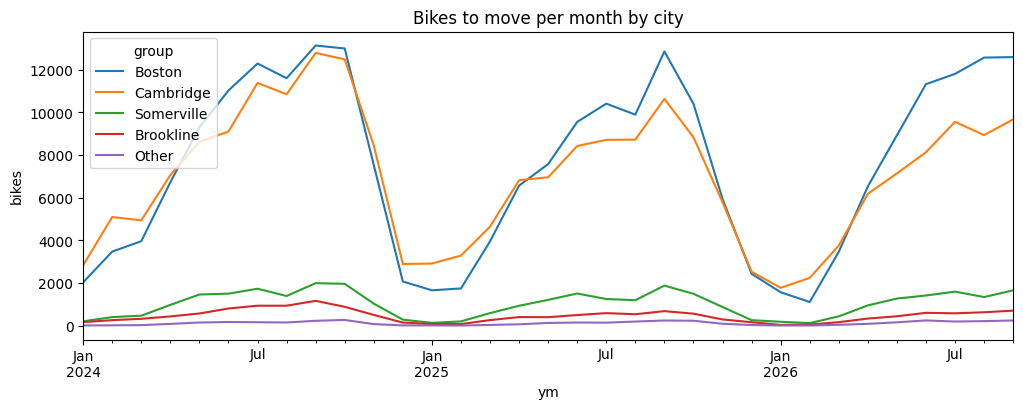

,Jan 2025,Jul 2025,Jul crews needed,Jan crews needed
group,,,,
Boston,1654.5,10406.0,3.3,0.5
Cambridge,2909.0,8708.0,2.7,0.9
Somerville,128.0,1246.0,0.4,0.0
Brookline,72.5,583.5,0.2,0.0
Other,9.5,137.5,0.0,0.0


In [4]:
def station_day_need(flow, st):
    f = flow.assign(date=flow.ts.dt.normalize(), hour=flow.ts.dt.hour, net=flow.inn - flow.out)
    pv = (f.pivot_table(index=["station", "date"], columns="hour", values="net", aggfunc="sum", fill_value=0)
            .reindex(columns=range(24), fill_value=0))
    docks = pv.index.get_level_values("station").map(st["docks"]).to_numpy(dtype=float)
    docks = np.where(np.isnan(docks), st.docks.median(), docks)
    X = pv.to_numpy(dtype=float)
    inv, short, over = docks / 2, np.zeros(len(pv)), np.zeros(len(pv))
    for h in range(24):
        inv = inv + X[:, h]
        short += np.clip(-inv, 0, None)
        over += np.clip(inv - docks, 0, None)
        inv = np.clip(inv, 0, docks)
    sd = pd.DataFrame({"short": short, "over": over}, index=pv.index).reset_index()
    sd["group"] = sd.station.map(st["group"]).fillna("Other")
    return sd

sd = station_day_need(flow, st)
all_days = pd.date_range("2024-01-01", "2026-09-30", freq="D")
city_daily = (sd.groupby(["group", "date"])[["short", "over"]].sum()
                .reindex(pd.MultiIndex.from_product([CITIES, all_days], names=["group", "date"]), fill_value=0)
                .reset_index())
city_daily["need"] = city_daily[["short", "over"]].max(axis=1)

city_month = (city_daily.assign(ym=city_daily.date.dt.to_period("M"))
                .groupby(["group", "ym"]).need.sum().unstack(0)[CITIES])
city_month.plot(figsize=(12, 4), title="Bikes to move per month by city"); plt.ylabel("bikes"); plt.show()

cmp = pd.DataFrame({"Jan 2025": city_month.loc["2025-01"], "Jul 2025": city_month.loc["2025-07"]})
cmp["Jul crews needed"] = (cmp["Jul 2025"] / (CAP_DAY * 31)).round(1)
cmp["Jan crews needed"] = (cmp["Jan 2025"] / (CAP_DAY * 31)).round(1)
cmp

## 4. GenAI: event extraction with structured output  `AI-assisted`
Raw event text → LLM → JSON validated by Pydantic → nearest stations → extra bikes to move on event days.

**Verify every text below against the official source (and cite it in the report).** Add the real 2026 Red Sox home schedule (redsox.com) as one more text; the LLM is told never to invent events.

In [6]:
from openai import OpenAI
from pydantic import BaseModel, Field

try:
    from google.colab import userdata
    api_key = userdata.get("OPENAI_API_KEY")
except Exception:
    api_key = os.environ.get("OPENAI_API_KEY")

if not api_key:
    print("WARNING: OPENAI_API_KEY not found. Please add it to Colab Secrets (key icon, left panel) or set it as an environment variable to use the OpenAI API.")
    client = None
else:
    client = OpenAI(api_key=api_key)

MODEL = "gpt-4o-mini"

EVENT_TEXTS = [  # VERIFY each against the official site; add sources to the report
    "The 130th Boston Marathon is on Patriots' Day, Monday April 20, 2026. Finish line on Boylston Street at Copley Square, Boston. About 30,000 runners and up to 500,000 spectators along the route.",
    "Boston Pops Fireworks Spectacular on July 4, 2026 at the Hatch Shell on the Charles River Esplanade, Boston. Several hundred thousand people expected for the nation's 250th anniversary.",
    "Head of the Charles Regatta, October 17-18, 2026, on the Charles River between Boston and Cambridge near Weld Boathouse and Harvard Square. Typically around 200,000 spectators over the weekend.",
    "Boston Calling Music Festival, May 22-24, 2026 at the Harvard Athletic Complex in Allston, Boston. Roughly 40,000 attendees per day.",
    "Allston Christmas / Sept 1 lease turnover and college move-in: Harvard, MIT, BU and Northeastern move-in runs roughly Aug 28 - Sept 2, 2026 across Cambridge (Harvard Square, MIT) and Boston (Allston, Fenway, Back Bay). Tens of thousands of students arriving.",
    # ADD the real Red Sox 2026 home schedule here as text, e.g.
    # "Red Sox home games at Fenway Park, Boston (capacity ~37,000): Apr 10-12 vs ...; Apr 13-15 vs ...; ..."
]

class Event(BaseModel):
    name: str
    start_date: date
    end_date: date
    location: str
    lat: float = Field(description="approximate venue latitude")
    lon: float = Field(description="approximate venue longitude")
    crowd_per_day: int = Field(description="expected attendees per day; estimate if not stated")
    confidence: float = Field(ge=0, le=1)

class EventList(BaseModel):
    events: list[Event]

SYSTEM = '''You extract events that change bike-share demand in Greater Boston.
Return ONLY JSON: {"events": [{"name", "start_date" (YYYY-MM-DD), "end_date", "location",
"lat", "lon", "crowd_per_day" (integer), "confidence" (0-1)}]}.
Rules: only events in 2026; one object per contiguous date range (a series of home games = one object per series);
if crowd size is a range use the midpoint; if missing, estimate from venue capacity and lower confidence;
give venue coordinates to 3 decimals. Never invent events that are not in the text.'''

def extract_events(text):
    if client is None:
        raise ValueError("OpenAI client is not initialized. Please set your OPENAI_API_KEY secret first.")
    r = client.chat.completions.create(
        model=MODEL, temperature=0, response_format={"type": "json_object"},
        messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": text}])
    return EventList.model_validate_json(r.choices[0].message.content).events

EV_CACHE = DATA / f"events_{abs(hash(tuple(EVENT_TEXTS))) % 10**8}.json"   # cache resets when texts change
if EV_CACHE.exists():
    events = [Event(**e) for e in json.loads(EV_CACHE.read_text())]
else:
    if client is None:
        print("No API key found and no cache exists. Please add OPENAI_API_KEY to run extraction.")
        events = []
    else:
        events = [e for t in EVENT_TEXTS for e in extract_events(t)]
        EV_CACHE.write_text(json.dumps([e.model_dump(mode="json") for e in events], indent=2))

if events:
    display(pd.DataFrame([e.model_dump() for e in events]))
else:
    print("No events loaded.")

,name,start_date,end_date,location,lat,lon,crowd_per_day,confidence
0,130th Boston Marathon,2026-04-20,2026-04-20,"Copley Square, Boston",42.349000,-71.078000,250000,0.9
1,Boston Pops Fireworks Spectacular,2026-07-04,2026-07-04,"Hatch Shell, Charles River Esplanade, Boston",42.354000,-71.071000,250000,1.0
2,Head of the Charles Regatta,2026-10-17,2026-10-18,Charles River between Boston and Cambridge nea...,42.373000,-71.126000,100000,0.9
3,Boston Calling Music Festival,2026-05-22,2026-05-24,Harvard Athletic Complex,42.349000,-71.133000,40000,1.0
4,Allston Christmas / College Move-In,2026-08-28,2026-09-02,Cambridge and Boston,42.373611,-71.109733,50000,0.9


In [7]:
def haversine_m(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 12_742_000 * np.arcsin(np.sqrt(a))

stn = st.dropna(subset=["lat", "lng"])
rows = []
for e in events:
    dist = haversine_m(e.lat, e.lon, stn.lat.values, stn.lng.values)
    near = stn[dist <= EVENT_RADIUS_M]
    if near.empty:
        near = stn.iloc[[dist.argmin()]]
    group = near.group.mode()[0]
    for d in pd.date_range(e.start_date, e.end_date):
        rows.append({"event": e.name, "date": d, "group": group,
                     "uplift": e.crowd_per_day * CROWD_BIKE_SHARE * e.confidence,
                     "stations": ", ".join(near.name.head(5))})
events_df = pd.DataFrame(rows)
event_days = events_df.groupby(["group", "date"], as_index=False).uplift.sum()
events_df.head(20)

,event,date,group,uplift,stations
0,130th Boston Marathon,2026-04-20,Boston,2250.0,"Boylston St at Fairfield St, Newbury St at Her..."
1,Boston Pops Fireworks Spectacular,2026-07-04,Boston,2500.0,"Dartmouth St at Newbury St, Beacon St at Charl..."
2,Head of the Charles Regatta,2026-10-17,Cambridge,900.0,"Craigie St at Brattle St/Sparks St, Church St,..."
3,Head of the Charles Regatta,2026-10-18,Cambridge,900.0,"Craigie St at Brattle St/Sparks St, Church St,..."
4,Boston Calling Music Festival,2026-05-22,Boston,400.0,"39 Brighton Ave, Franklin St at Cambridge St, ..."
5,Boston Calling Music Festival,2026-05-23,Boston,400.0,"39 Brighton Ave, Franklin St at Cambridge St, ..."
6,Boston Calling Music Festival,2026-05-24,Boston,400.0,"39 Brighton Ave, Franklin St at Cambridge St, ..."
7,Allston Christmas / College Move-In,2026-08-28,Cambridge,450.0,Harvard University Gund Hall at Quincy St / Ki...
8,Allston Christmas / College Move-In,2026-08-29,Cambridge,450.0,Harvard University Gund Hall at Quincy St / Ki...
9,Allston Christmas / College Move-In,2026-08-30,Cambridge,450.0,Harvard University Gund Hall at Quincy St / Ki...


## 5. Event-aware 2026 forecast
For each city and month we keep the **daily** need from 2024 and 2025 (scaled by the observed 2024→2025 growth, extrapolated 1.5 years) as equally likely 'sample days', plus one sample per 2026 event day (typical day + event uplift). Planning on daily samples, not monthly totals, means peak days count.

In [8]:
hist = city_daily[city_daily.date.dt.year.isin([2024, 2025])]
yr = hist.groupby(["group", hist.date.dt.year]).need.sum().unstack()
growth = ((yr[2025] / yr[2024]) ** 1.5).clip(0.8, 1.5).reindex(CITIES).fillna(1.0)
print("growth factor to 2026:\n", growth.round(3))

def build_samples(scale=1.0):
    rows = []
    for c in CITIES:
        hc = hist[hist.group == c]
        for t in range(1, 13):
            h = hc[hc.date.dt.month == t].need.to_numpy() * growth[c] * scale
            ev = event_days[(event_days.group == c) & (event_days.date.dt.month == t)]
            w = (DAYS26[t] - len(ev)) / len(h)
            rows += [(c, t, v, w) for v in h]
            rows += [(c, t, np.median(h) + u * scale, 1.0) for u in ev.uplift]
    return pd.DataFrame(rows, columns=["city", "month", "need", "weight"])

S_BASE = build_samples()
fc = S_BASE.assign(tot=S_BASE.need * S_BASE.weight).groupby(["city", "month"]).tot.sum().unstack(0)[CITIES]
fc.round(0)

growth factor to 2026:
 group
Boston        0.802
Cambridge     0.800
Somerville    0.800
Brookline     0.800
Other         0.974
dtype: float64


city,Boston,Cambridge,Somerville,Brookline,Other
month,,,,,
1,1476.0,2297.0,131.0,94.0,8.0
2,2053.0,3291.0,233.0,128.0,7.0
3,3172.0,3831.0,419.0,230.0,26.0
4,7588.0,5549.0,760.0,332.0,69.0
5,7989.0,6226.0,1066.0,385.0,131.0
6,8251.0,7009.0,1200.0,518.0,152.0
7,11649.0,8034.0,1190.0,606.0,144.0
8,8619.0,9716.0,1031.0,586.0,163.0
9,10422.0,10402.0,1546.0,735.0,225.0


## 6. Dynamic staffing model (integer program)
Decision variables per city *c*, month *t*: full-time crews `F`, hires `H` (start recruiting in *t*, first shift *t+1*), releases `R` (notice in *t*, gone in *t+1*), active seasonal crews `S`, new seasonal starts `K` (signed in *t−1*). Constraints: brief's lead times, 3-month seasonal minimum, ≤ 8 seasonal crews system-wide. Objective: crew cost + severance + expected lost revenue on unmoved bikes.

In [9]:
def plan_crews(samples, seasonal_cap=SEASONAL_CAP, time_limit=120):
    T = list(range(1, 13))
    samples = samples.reset_index(drop=True).copy()
    samples["need"] = samples["need"].fillna(0.0)
    idx = {}
    for k in ["F", "H", "R", "S", "K"]:          # full-time, hires, releases, seasonal active, seasonal starts
        for c in CITIES:
            for t in T:
                idx[(k, c, t)] = len(idx)
    X = lambda k, c, t: idx[(k, c, t)]
    n_int = len(idx); n = n_int + len(samples)    # + one 'unmoved bikes' variable per sample day

    rows, cols, vals, lo, hi = [], [], [], [], []
    def add(terms, l, u):
        r = len(lo)
        for j, a in terms:
            rows.append(r); cols.append(j); vals.append(a)
        lo.append(l); hi.append(u)

    for c in CITIES:
        for t in T:
            if t == 1:
                add([(X("F", c, 1), 1)], INIT_CREWS[c], INIT_CREWS[c])
                add([(X("K", c, 1), 1)], 0, 0)
                add([(X("S", c, 1), 1), (X("K", c, 1), -1)], -np.inf, 0)
            else:   # hire in t-1 -> works from t ; notice in t-1 -> gone in t
                add([(X("F", c, t), 1), (X("F", c, t-1), -1), (X("H", c, t-1), -1), (X("R", c, t-1), 1)], 0, 0)
                add([(X("S", c, t), 1), (X("S", c, t-1), -1), (X("K", c, t), -1)], -np.inf, 0)
            add([(X("R", c, t), 1), (X("F", c, t), -1)], -np.inf, 0)
            add([(X("S", c, t), 1)] + [(X("K", c, k), -1) for k in range(max(1, t - SEASONAL_MIN + 1), t + 1)], 0, np.inf)
        add([(X("H", c, 12), 1)], 0, 0)
        add([(X("R", c, 12), 1)], 0, 0)
    for t in T:
        add([(X("S", c, t), 1) for c in CITIES], -np.inf, seasonal_cap)
    for i, r in enumerate(samples.itertuples()):   # unmoved + capacity >= need
        add([(n_int + i, 1), (X("F", r.city, r.month), CAP_DAY), (X("S", r.city, r.month), CAP_DAY)], r.need, np.inf)

    A = sp.csr_matrix((vals, (rows, cols)), shape=(len(lo), n))
    cost = np.zeros(n)
    for c in CITIES:
        for t in T:
            cost[X("F", c, t)] = FT_MONTHLY
            cost[X("R", c, t)] = RELEASE_COST
            cost[X("S", c, t)] = SEASONAL_MONTHLY
    cost[n_int:] = LOSS_PER_FAILED * UNMET_TO_FAILED * samples.weight.to_numpy()

    res = milp(c=cost, constraints=LinearConstraint(A, lo, hi),
               integrality=np.r_[np.ones(n_int), np.zeros(len(samples))],
               bounds=Bounds(0, np.inf), options={"time_limit": time_limit})
    print("solver (SciPy/HiGHS):", res.message)
    if res.x is None:
        raise RuntimeError("No solution found - try a larger time_limit")
    v = lambda k, c, t: int(round(res.x[X(k, c, t)]))
    plan = pd.DataFrame([{"city": c, "month": t, "full_time": v("F", c, t), "seasonal": v("S", c, t),
                          "start_recruiting": v("H", c, t), "give_notice": v("R", c, t),
                          "sign_seasonal_for_next_month": v("K", c, t + 1) if t < 12 else 0}
                         for c in CITIES for t in T])
    plan["total_crews"] = plan.full_time + plan.seasonal
    return plan

def expected_shortfall(c, t, crews, samples):
    s = samples[(samples.city == c) & (samples.month == t)]
    return float((s.weight * np.clip(s.need - CAP_DAY * crews, 0, None)).sum())

def cost_table(plan, samples):
    p = plan.copy()
    p["crew_cost"] = p.full_time * FT_MONTHLY + p.seasonal * SEASONAL_MONTHLY + p.give_notice * RELEASE_COST
    p["exp_unmoved_bikes"] = [expected_shortfall(r.city, r.month, r.total_crews, samples) for r in p.itertuples()]
    p["exp_lost_revenue"] = p.exp_unmoved_bikes * UNMET_TO_FAILED * LOSS_PER_FAILED
    return p

plan = cost_table(plan_crews(S_BASE), S_BASE)
status_quo = cost_table(pd.DataFrame([{"city": c, "month": t, "full_time": INIT_CREWS[c], "seasonal": 0,
                                       "start_recruiting": 0, "give_notice": 0, "sign_seasonal_for_next_month": 0,
                                       "total_crews": INIT_CREWS[c]} for c in CITIES for t in range(1, 13)]), S_BASE)
summary = pd.DataFrame({k: [d.crew_cost.sum(), d.exp_lost_revenue.sum(), d.crew_cost.sum() + d.exp_lost_revenue.sum()]
                        for k, d in {"optimized plan": plan, "keep Jan crews all year": status_quo}.items()},
                       index=["crew cost", "expected lost revenue", "total"]).round(0)
display(summary)
plan.pivot(index="month", columns="city", values=["full_time", "seasonal"])

solver (SciPy/HiGHS): Optimization terminated successfully. (HiGHS Status 7: Optimal)


,optimized plan,keep Jan crews all year
crew cost,663900.0,1008000.0
expected lost revenue,153225.0,49880.0
total,817125.0,1057880.0


full_time                                      seasonal            \
city     Boston Brookline Cambridge Other Somerville   Boston Brookline   
month                                                                     
1             6         1         4     2          1        0         0   
2             3         0         3     0          1        0         0   
3             3         0         3     0          1        0         0   
4             3         0         3     0          1        0         0   
5             3         0         3     0          1        0         0   
6             3         0         3     0          1        0         0   
7             3         0         3     0          1        0         0   
8             3         0         3     0          1        1         0   
9             3         0         3     0          1        1         0   
10            3         0         3     0          1        1         0   
11            3         0         3     0          1        0         0   
12            3         0         3     0          1        0         0   

                                  
city  Cambridge Other Somerville  
month                             
1             0     0          0  
2             0     0          0  
3             0     0          0  
4             0     0          0  
5             0     0          0  
6             0     0          0  
7             0     0          0  
8             0     0          0  
9             0     0          0  
10            0     0          0  
11            0     0          0  
12            0     0          0

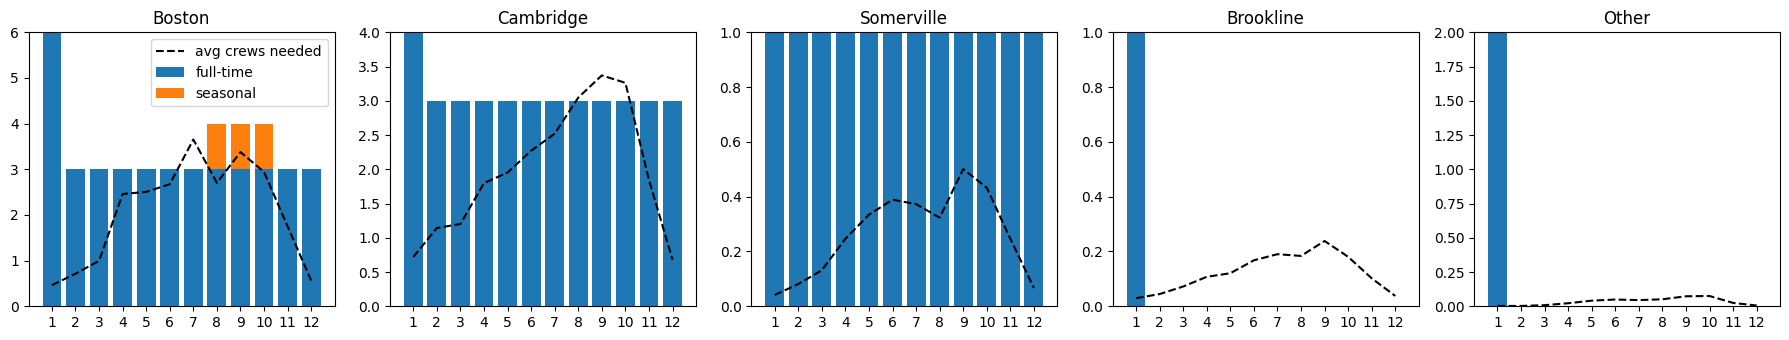

,city,month,start_recruiting,give_notice,sign_seasonal_for_next_month
0,Boston,1,0,3,0
6,Boston,7,0,0,1
12,Cambridge,1,0,1,0
36,Brookline,1,0,1,0
48,Other,1,0,2,0


In [10]:
fig, axes = plt.subplots(1, len(CITIES), figsize=(18, 3.5), sharex=True)
for ax, c in zip(axes, CITIES):
    p = plan[plan.city == c]
    ax.bar(p.month, p.full_time, label="full-time")
    ax.bar(p.month, p.seasonal, bottom=p.full_time, label="seasonal")
    ax.plot(p.month, fc[c].values / (CAP_DAY * np.array(list(DAYS26.values()))), "k--", label="avg crews needed")
    ax.set_title(c); ax.set_xticks(range(1, 13))
axes[0].legend(); plt.tight_layout(); plt.show()

actions = plan[(plan.start_recruiting > 0) | (plan.give_notice > 0) | (plan.sign_seasonal_for_next_month > 0)]
actions[["city", "month", "start_recruiting", "give_notice", "sign_seasonal_for_next_month"]]

## 7. Backtest against real Jan–Sep 2026 trips

In [11]:
def backtest(plan):
    a = city_daily[(city_daily.date >= "2026-01-01") & (city_daily.date <= "2026-09-30")].copy()
    a["month"] = a.date.dt.month
    a = a.merge(plan[["city", "month", "total_crews"]], left_on=["group", "month"], right_on=["city", "month"])
    a["capacity"] = a.total_crews * CAP_DAY
    a["unmoved"] = np.clip(a.need - a.capacity, 0, None)
    a["lost_rev"] = a.unmoved * UNMET_TO_FAILED * LOSS_PER_FAILED
    return a

bt = backtest(plan); bt_sq = backtest(status_quo)
bt_month = bt.groupby(["group", "month"]).agg(actual_need=("need", "sum"), capacity=("capacity", "sum"),
                                              unmoved=("unmoved", "sum"), short_days=("unmoved", lambda x: (x > 0).sum()),
                                              lost_rev=("lost_rev", "sum")).round(0)
print(f"Lost revenue Jan-Sep 2026 | optimized plan: ${bt.lost_rev.sum():,.0f} | status quo: ${bt_sq.lost_rev.sum():,.0f}")
fc_vs_actual = pd.DataFrame({"forecast": fc.loc[1:9].stack(),
                             "actual": bt.groupby(["month", "group"]).need.sum()}).dropna()
fc_vs_actual["error_%"] = (100 * (fc_vs_actual.forecast - fc_vs_actual.actual) / fc_vs_actual.actual).round(1)
display(fc_vs_actual)
bt_month.sort_values("lost_rev", ascending=False).head(10)   # where crews fell short most

Lost revenue Jan-Sep 2026 | optimized plan: $155,685 | status quo: $13,607


forecast   actual  error_%
month                                           
1     Boston       1476.042814   1564.0     -5.6
      Brookline      94.400000     32.5    190.5
      Cambridge    2296.600000   1771.0     29.7
      Other           7.549748      5.5     37.3
      Somerville    130.800000    179.0    -26.9
2     Boston       2053.176936   1105.5     85.7
      Brookline     128.308772     47.5    170.1
      Cambridge    3291.424561   2237.0     47.1
      Other           7.178029      4.0     79.5
      Somerville    233.431579    115.5    102.1
3     Boston       3172.058317   3459.5     -8.3
      Brookline     230.000000    160.5     43.3
      Cambridge    3831.000000   3752.5      2.1
      Other          25.571727     36.5    -29.9
      Somerville    419.400000    432.5     -3.0
4     Boston       7587.582833   6527.0     16.2
      Brookline     332.000000    329.0      0.9
      Cambridge    5549.400000   6178.5    -10.2
      Other          68.678352     82.0    -16.2
      Somerville    760.400000    946.5    -19.7
5     Boston       7989.016847   8920.0    -10.4
      Brookline     384.600000    436.5    -11.9
      Cambridge    6226.400000   7135.5    -12.7
      Other         130.537576    153.5    -15.0
      Somerville   1065.800000   1268.0    -15.9
6     Boston       8251.281855  11320.0    -27.1
      Brookline     517.800000    598.0    -13.4
      Cambridge    7009.400000   8127.5    -13.8
      Other         151.969118    242.5    -37.3
      Somerville   1200.400000   1410.5    -14.9
7     Boston      11648.605094  11802.0     -1.3
      Brookline     606.400000    575.5      5.4
      Cambridge    8034.200000   9555.0    -15.9
      Other         143.688750    189.5    -24.2
      Somerville   1189.600000   1592.0    -25.3
8     Boston       8619.039296  12565.0    -31.4
      Brookline     586.000000    625.0     -6.2
      Cambridge    9716.090323   8930.0      8.8
      Other         162.928430    209.0    -22.0
      Somerville   1031.000000   1338.0    -22.9
9     Boston      10421.532008  12589.5    -17.2
      Brookline     735.400000    700.5      5.0
      Cambridge   10402.373333   9666.0      7.6
      Other         225.274735    239.5     -5.9
      Somerville   1545.800000   1653.5     -6.5

actual_need  capacity  unmoved  short_days  lost_rev
group     month                                                      
Boston    7          11802.0    9566.0   3449.0          22   19659.0
          6          11320.0    9257.0   3224.0          18   18375.0
          9          12590.0   12343.0   3096.0          17   17648.0
Cambridge 9           9666.0    9257.0   2531.0          19   14428.0
Boston    8          12565.0   12754.0   2384.0          16   13587.0
Cambridge 7           9555.0    9566.0   2137.0          18   12182.0
Boston    5           8920.0    9566.0   1891.0          17   10777.0
Cambridge 8           8930.0    9566.0   1654.0          17    9429.0
          6           8128.0    9257.0   1028.0          14    5860.0
Brookline 9            700.0       0.0    700.0          29    3993.0

## 8. Sensitivity: ridership ±20% and e-bike growth

In [12]:
eb = stats.assign(year=stats.month.str[:4]).groupby(["year", "rideable_type"]).trips.sum().unstack()
eb_share = (eb["electric_bike"] / eb.sum(axis=1)).round(3)
print("e-bike share of trips by year:\n", eb_share)

EBIKE_SHARE_BUMP = 0.15     # assumption: e-bike share 15 points higher than trend
EBIKE_IMB_MULT = 1.30       # assumption: an e-bike trip creates 30% more imbalance (longer, more one-way trips)
scenarios = {"base": 1.0, "ridership +20%": 1.2, "ridership -20%": 0.8,
             "e-bike growth": 1 + EBIKE_SHARE_BUMP * (EBIKE_IMB_MULT - 1)}
rows = []
for name, k in scenarios.items():
    s = build_samples(k)
    re_plan = cost_table(plan_crews(s), s)
    base_under = cost_table(plan, s)        # what happens if we keep the base plan and this scenario happens
    rows.append({"scenario": name, "replanned cost": re_plan.crew_cost.sum(),
                 "replanned lost rev": re_plan.exp_lost_revenue.sum(),
                 "peak crews": re_plan.groupby("month").total_crews.sum().max(),
                 "peak seasonal": re_plan.groupby("month").seasonal.sum().max(),
                 "base plan lost rev": base_under.exp_lost_revenue.sum()})
pd.DataFrame(rows).round(0)

e-bike share of trips by year:
 year
2024    0.255
2025    0.285
2026    0.319
dtype: float64
solver (SciPy/HiGHS): Optimization terminated successfully. (HiGHS Status 7: Optimal)
solver (SciPy/HiGHS): Optimization terminated successfully. (HiGHS Status 7: Optimal)
solver (SciPy/HiGHS): Optimization terminated successfully. (HiGHS Status 7: Optimal)
solver (SciPy/HiGHS): Optimization terminated successfully. (HiGHS Status 7: Optimal)


,scenario,replanned cost,replanned lost rev,peak crews,peak seasonal,base plan lost rev
0,base,663900.0,153225.0,14,1,153225.0
1,ridership +20%,730500.0,180899.0,14,0,261174.0
2,ridership -20%,537600.0,173157.0,14,2,79883.0
3,e-bike growth,695100.0,141347.0,14,2,174864.0


## 9. Operations assistant (agent with tool calling)  `AI-assisted`
The LLM never computes numbers itself; it calls our model through tools.

In [13]:
station_hot = (sd[sd.date.dt.year.isin([2024, 2025])].assign(month=lambda d: d.date.dt.month)
                 .groupby(["group", "month", "station"])[["short", "over"]].mean().reset_index())

def get_plan(city, month):
    r = plan[(plan.city == city) & (plan.month == month)].iloc[0]
    return {k: (int(v) if isinstance(v, (np.integer, int)) else round(float(v), 1) if isinstance(v, float) else v)
            for k, v in r.items()}

def what_if(city, month, add_crews, crew_type="seasonal"):
    base = int(plan[(plan.city == city) & (plan.month == month)].total_crews.iloc[0])
    b0, b1 = (expected_shortfall(city, month, n, S_BASE) for n in (base, base + add_crews))
    cost = add_crews * (SEASONAL_MONTHLY if crew_type == "seasonal" else FT_MONTHLY)
    out = {"city": city, "month": month, "crews_before": base, "crews_after": base + add_crews,
           "expected_unmoved_bikes_before": round(b0), "expected_unmoved_bikes_after": round(b1),
           "revenue_recovered": round((b0 - b1) * LOSS_PER_FAILED), "added_crew_cost": cost,
           "net_benefit": round((b0 - b1) * LOSS_PER_FAILED - cost)}
    if crew_type == "seasonal":
        out["note"] = f"seasonal contracts run at least {SEASONAL_MIN} months and must be signed the month before"
    return out

def risky_stations(city, month, kind="empty", top=5):
    col = "short" if kind == "empty" else "over"
    d = station_hot[(station_hot.group == city) & (station_hot.month == month)].nlargest(top, col)
    return [{"station": st.loc[s, "name"] if s in st.index else s, f"avg_bikes_{'needed' if kind == 'empty' else 'to_remove'}_per_day": round(v, 1)}
            for s, v in zip(d.station, d[col])]

def list_events(month, city=None):
    e = events_df[events_df.date.dt.month == month]
    if city: e = e[e.group == city]
    return e.groupby("event").agg(first_day=("date", "min"), days=("date", "count"), city=("group", "first"),
                                  stations=("stations", "first")).reset_index().astype(str).to_dict("records")

TOOLS = {"get_plan": get_plan, "what_if": what_if, "risky_stations": risky_stations, "list_events": list_events}
city_p = {"type": "string", "enum": CITIES}; month_p = {"type": "integer", "minimum": 1, "maximum": 12}
TOOL_SPECS = [
    {"type": "function", "function": {"name": "get_plan", "description": "Crew plan for a city and month of 2026",
        "parameters": {"type": "object", "properties": {"city": city_p, "month": month_p}, "required": ["city", "month"]}}},
    {"type": "function", "function": {"name": "what_if", "description": "Effect of adding (or removing, negative) crews in a city-month",
        "parameters": {"type": "object", "properties": {"city": city_p, "month": month_p, "add_crews": {"type": "integer"},
                       "crew_type": {"type": "string", "enum": ["seasonal", "full_time"]}}, "required": ["city", "month", "add_crews"]}}},
    {"type": "function", "function": {"name": "risky_stations", "description": "Stations most likely to run empty or full",
        "parameters": {"type": "object", "properties": {"city": city_p, "month": month_p, "kind": {"type": "string", "enum": ["empty", "full"]}},
                       "required": ["city", "month"]}}},
    {"type": "function", "function": {"name": "list_events", "description": "Events in a month (optionally a city) and nearby stations",
        "parameters": {"type": "object", "properties": {"month": month_p, "city": city_p}, "required": ["month"]}}},
]
OPS_SYSTEM = ("You are the Bluebikes rebalancing operations assistant. Always answer from tool results, never guess numbers. "
              "Be brief: give the numbers, then a one-line recommendation. Months are 2026.")

def ask(question, max_steps=6):
    msgs = [{"role": "system", "content": OPS_SYSTEM}, {"role": "user", "content": question}]
    for _ in range(max_steps):
        r = client.chat.completions.create(model=MODEL, messages=msgs, tools=TOOL_SPECS, temperature=0)
        m = r.choices[0].message
        if not m.tool_calls:
            return m.content
        msgs.append(m.model_dump(exclude_none=True))
        for tc in m.tool_calls:
            result = TOOLS[tc.function.name](**json.loads(tc.function.arguments))
            msgs.append({"role": "tool", "tool_call_id": tc.id, "content": json.dumps(result, default=str)})
    return "Stopped: too many tool steps."

for q in ["What happens if we add one crew to Cambridge in September?",
          "Which Boston stations are most likely to run empty in July, and what events are on that month?",
          "How many seasonal crews do we have across the system in August, and when do we need to sign them?"]:
    print("Q:", q, "\nA:", ask(q), "\n")

Q: What happens if we add one crew to Cambridge in September? 
A: Adding one crew to Cambridge in September would reduce expected unmoved bikes from 3000 to 1298, recover $9700 in revenue, cost $7800, resulting in a net benefit of $1900. 

Recommendation: Proceed with adding the crew for improved efficiency. 

Q: Which Boston stations are most likely to run empty in July, and what events are on that month? 
A: **Empty Stations in Boston (July):**
1. Longwood Ave at Binney St - 41.0 avg bikes needed/day
2. (retired) near Nashua Street at Red Auerbach Way [Extension] - 7.3 avg bikes needed/day
3. W Broadway at D St - 6.6 avg bikes needed/day
4. Brighton Ave at Linden St - 6.0 avg bikes needed/day
5. W Broadway at Dorchester St - 5.6 avg bikes needed/day

**Event in Boston (July):**
- Boston Pops Fireworks Spectacular on July 4th.

**Recommendation:** Focus rebalancing efforts at Longwood Ave at Binney St and prepare for increased demand around the July 4th event. 

Q: How many seasonal c

## 10. Analysis report  `AI-assisted: drafted from our notebook outputs, reviewed by the team`

### Method & assumptions
- **Rebalancing need:** each station starts the day half full; we replay hourly net flow and count bikes that must be brought in (station would go below 0) or taken out (above its dock count). A city's daily bikes-to-move = max(bring-in, take-out), since one van move fixes one of each.
- **Cost of an unmoved bike:** one unmoved bike = one failed rider attempt, costing $5.70 in expectation (brief: 40% still ride, 45% lose $3.25, 15% lose $3.25 + $25).
- **Forecast:** daily need from 2024–2025 used as sample days for each 2026 month, scaled by the 2024→2025 growth trend (clipped to 0.8–1.5), plus one sample per 2026 event day.
- **Crews:** capacity 120 bikes × 6 shifts/week ≈ 103 bikes per calendar day; January 2026 crews treated as full-time; brief's hiring, notice, severance and seasonal rules modelled exactly; integer program solved with SciPy `milp` (HiGHS) to minimise crew cost + severance + expected lost revenue.
- **Stations:** the official station CSV's IDs did not match trip IDs, so stations were mapped with the live Bluebikes GBFS feed (station number + region); retired stations take the city of the nearest current station. Result: Boston 56.6%, Cambridge 32.0%, Somerville 5.9%, Brookline 2.6%, other cities 2.9% of trips.

### What the data shows
Imbalance is strongly seasonal: Boston needed about 10,400 bikes moved in July 2025 vs 1,650 in January (6×); Cambridge 8,700 vs 2,900 (3×). On this measure the January crew levels (14 crews) are far above winter need, while Boston and Cambridge summer peaks are close to or above their capacity.

### Key decisions (2026 plan)
- **January:** give notice to 7 full-time crews (Boston 3, Cambridge 1, Brookline 1, other cities 2). From February the base is Boston 3, Cambridge 3, Somerville 1 full-time.
- **Seasonal:** sign 1 seasonal crew for Boston in July, working August–October (meets the 3-month minimum). The 8-crew seasonal cap never binds.
- **Why so lean:** a crew-month costs $6,000 (full-time) or $7,800 (seasonal). At $5.70 per unmoved bike, a crew only pays for itself if it moves at least ~1,050 (full-time) or ~1,370 (seasonal) bikes a month that would otherwise go unmoved, out of ~3,100 it can move. Releasing a driver costs $13,500, about 2.25 months of pay, so the model releases early in January and keeps the remaining base all year.

### Cost & revenue impact (full year 2026, expected)
| | Crew cost | Expected lost revenue | Total |
|---|---|---|---|
| Optimized plan | $663,900 | $153,225 | $817,125 |
| Keep January crews all year | $1,008,000 | $49,880 | $1,057,880 |

The plan saves about **$241,000 (23%)**: it accepts ~$103,000 more lost revenue to save ~$344,000 in crew cost.

### Backtest on real Jan–Sep 2026 trips
- **Overall:** plan crew cost ≈ $530,100 + lost revenue $155,685 ≈ $685,800, vs status quo ≈ $756,000 + $13,607 ≈ $769,600. The plan still comes out ~$84,000 ahead on real 2026 data.
- **Where crews fell short:** Boston in July (3,449 unmoved bikes, 22 short days), June and September; Cambridge in September and July; Brookline in September (700 unmoved with no crew).
- **Forecast error:** winter was over-forecast (e.g. Boston February +86%), summer under-forecast by 15–31% (Boston June −27%, August −31%). The 2024→2025 trend was negative and clipped at 0.80, but 2026 demand rebounded, so the trend assumption is the main source of error.

### Sensitivity
| Scenario | Re-planned crew cost | Re-planned lost revenue | Lost revenue if we keep the base plan |
|---|---|---|---|
| Base | $663,900 | $153,225 | $153,225 |
| Ridership +20% | $730,500 | $180,899 | $261,174 |
| Ridership −20% | $537,600 | $173,157 | $79,883 |
| E-bike growth | $695,100 | $141,347 | $174,864 |

E-bike share rose from 25.5% (2024) to 28.5% (2025) to 31.9% (2026). The base plan is most exposed to higher ridership: lost revenue rises ~70% if demand is 20% higher, so the summer seasonal decision should be revisited each spring.

### Operations assistant
The tool-calling assistant answers from model outputs. Adding one crew to Cambridge in September cuts expected unmoved bikes from ~3,000 to ~1,298 and recovers ~$9,700 against $7,800 of cost. However, a seasonal crew must be contracted for 3 months, so the real cost is ~$23,400 unless October and November also benefit, which the assistant did not flag. Its answer about August seasonal crews was also wrong (it reported 0; the plan has 1 in Boston), because it looked up only one city. Both show the assistant needs a system-wide summary tool and the contract rules built into `what_if`.

### Recommendations
- Keep a Boston/Cambridge summer buffer: given the backtest shortfalls, add 1–2 seasonal crews for June–September in Boston and Cambridge, signed in May.
- Keep a shared crew covering Brookline in late summer rather than none.
- Add docks or valet service at chronic hot spots (e.g. Longwood Ave at Binney St), and trial rider rewards for returning bikes to stations that drain.

### Limitations
- Trip data shows only completed trips, so demand lost when a station was empty or full is invisible; need is understated.
- The daily half-full reset ignores overnight carry-over.
- There is no weather variable and no Red Sox schedule yet; event dates and crowd sizes need to be verified against official sources.
- Crowd-to-bike share (1%) and e-bike imbalance (+30%) are assumptions.

### Data sources
Bluebikes trip histories (s3.amazonaws.com/hubway-data) and the Bluebikes station list and GBFS feed (bluebikes.com/system-data), used under the Bluebikes Data License Agreement. Event sources: *(add the official pages you used)*.